In [33]:
# Install CUDA-enabled PyTorch
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
  Using cached https://download-r2.pytorch.org/whl/cu128/torch-2.11.0%2Bcu128-cp314-cp314-win_amd64.whl.metadata (29 kB)
  Using cached https://download-r2.pytorch.org/whl/cu128/torchvision-0.26.0%2Bcu128-cp314-cp314-win_amd64.whl.metadata (5.6 kB)
Using cached https://download-r2.pytorch.org/whl/cu128/torch-2.11.0%2Bcu128-cp314-cp314-win_amd64.whl (2771.0 MB)
Using cached https://download-r2.pytorch.org/whl/cu128/torchvision-0.26.0%2Bcu128-cp314-cp314-win_amd64.whl (9.7 MB)

   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------

In [36]:
# ============================================================
# Cell 4 — Imports
# ============================================================

from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split

from torchvision import datasets, transforms, models

from sklearn.metrics import classification_report, confusion_matrix

In [37]:
# ============================================================
# Cell 5 — Configuration
# ============================================================

# Main dataset folder
CT_DIR1 = Path(r"D:\Media\EDU\NUS\GC2\PROJ\raw data\hrct-chest-covid-data-ct-scan\HRCT-Chest-Covid-Data-CT-SCAN\HRCT Chest Covid Data CT SCAN")
# Class folders
COVID_DIR = CT_DIR1 / "Covid"
NORMAL_DIR = CT_DIR1 / "Normal"

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 5
LEARNING_RATE = 0.001
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Training device: cuda
GPU: NVIDIA GeForce RTX 3060 Ti


In [38]:
# ============================================================
# Cell 6 — CHECK DATASET
# ============================================================

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def get_images(folder):
    return [
        file for file in folder.rglob("*")
        if file.suffix.lower() in IMAGE_EXTENSIONS
    ]

covid_images = get_images(COVID_DIR)
normal_images = get_images(NORMAL_DIR)

print("COVID folder :", COVID_DIR)
print("NORMAL folder:", NORMAL_DIR)

print("\nCOVID images :", len(covid_images))
print("NORMAL images:", len(normal_images))

assert COVID_DIR.exists(), "COVID folder does not exist."
assert NORMAL_DIR.exists(), "NORMAL folder does not exist."
assert len(covid_images) > 0, "No COVID images found."
assert len(normal_images) > 0, "No NORMAL images found."

COVID folder : D:\Media\EDU\NUS\GC2\PROJ\raw data\hrct-chest-covid-data-ct-scan\HRCT-Chest-Covid-Data-CT-SCAN\HRCT Chest Covid Data CT SCAN\Covid
NORMAL folder: D:\Media\EDU\NUS\GC2\PROJ\raw data\hrct-chest-covid-data-ct-scan\HRCT-Chest-Covid-Data-CT-SCAN\HRCT Chest Covid Data CT SCAN\Normal

COVID images : 2242
NORMAL images: 3840


In [39]:
# ============================================================
# Cell 7 — CUSTOM TWO-FOLDER DATASET
# ============================================================

from PIL import Image
from torch.utils.data import Dataset

class CTDataset(Dataset):

    def __init__(self, covid_dir, normal_dir, transform=None):

        self.transform = transform

        covid_files = get_images(covid_dir)
        normal_files = get_images(normal_dir)

        # Label 0 = NORMAL
        # Label 1 = COVID
        self.samples = (
            [(file, 1) for file in covid_files] +
            [(file, 0) for file in normal_files]
        )

        random.Random(SEED).shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        path, label = self.samples[index]

        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [40]:
# ============================================================
# Cell 8 — IMAGE PREPROCESSING
# ============================================================

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),

    # ImageNet normalization for pretrained ResNet
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = CTDataset(
    COVID_DIR,
    NORMAL_DIR,
    transform=transform
)

print("Total images:", len(dataset))

Total images: 6082


In [41]:
# ============================================================
# Cell 9 — TRAIN / VALIDATION SPLIT
# ============================================================

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images  :", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images  : 4865
Validation images: 1217


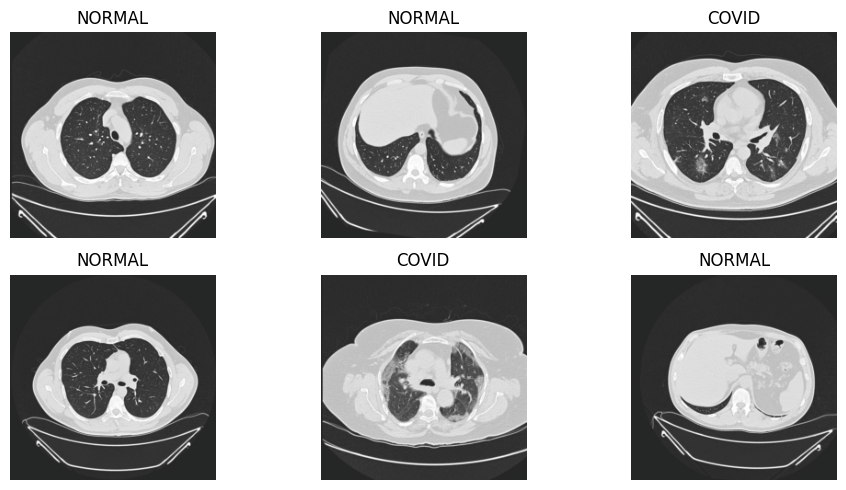

In [42]:
# ============================================================
# Cell 10 — VISUAL DATA CHECK
# ============================================================

class_names = ["NORMAL", "COVID"]

images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(min(6, len(images))):

    image = images[i].permute(1, 2, 0).numpy()

    # Undo ImageNet normalization for display
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = std * image + mean
    image = np.clip(image, 0, 1)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# Cell 11 — MODEL: RESNET18
# ============================================================

model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace original ImageNet classifier with 2 classes
model.fc = nn.Linear(
    model.fc.in_features,
    2
)

model = model.to(device)

print(model.fc)

Linear(in_features=512, out_features=2, bias=True)


In [44]:
# ============================================================
# Cell 12 — Loss function and optimizer TRAINING SETTINGS
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss      :", criterion)
print("Optimizer :", optimizer.__class__.__name__)
print("LR        :", LEARNING_RATE)

Loss      : CrossEntropyLoss()
Optimizer : Adam
LR        : 0.001


In [45]:
# ============================================================
# Cell 13 — Training loop
# ============================================================

train_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    # ---------------- TRAIN ----------------
    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # ---------------- VALIDATE ----------------
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total

    train_losses.append(train_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch 1/5 | Loss: 0.0856 | Val Accuracy: 0.9885
Epoch 2/5 | Loss: 0.0509 | Val Accuracy: 0.9967
Epoch 3/5 | Loss: 0.0299 | Val Accuracy: 0.9992
Epoch 4/5 | Loss: 0.0179 | Val Accuracy: 1.0000
Epoch 5/5 | Loss: 0.0025 | Val Accuracy: 1.0000


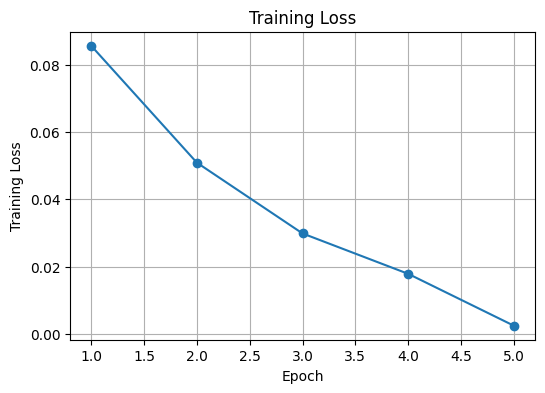

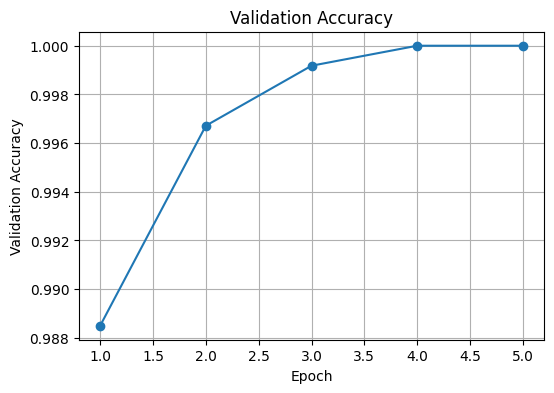

In [46]:
# ============================================================
# Cell 14 — Plot initial training results
# ============================================================

plt.figure(figsize=(6, 4))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")
plt.grid(True)

plt.show()


plt.figure(figsize=(6, 4))

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy")
plt.grid(True)

plt.show()

In [47]:
# ============================================================
# Cell 15 — Full validation evaluation
# ============================================================

model.eval()

true_labels = []
predicted_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1).cpu()

        true_labels.extend(labels.numpy())
        predicted_labels.extend(predictions.numpy())

print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=class_names,
        digits=2
    )
)

              precision    recall  f1-score   support

      NORMAL       1.00      1.00      1.00       786
       COVID       1.00      1.00      1.00       431

    accuracy                           1.00      1217
   macro avg       1.00      1.00      1.00      1217
weighted avg       1.00      1.00      1.00      1217



## Classification Metrics Summary

| Metric | Key Meaning |
|---|---|
| **Precision** | How reliable the model's prediction is. |
| **Recall** | How many actual cases the model detects. |
| **Sensitivity** | Recall for the disease/positive class. |
| **F1-score** | Balance between precision and recall. |
| **Support** | Number of actual samples tested. |
| **Accuracy** | Overall percentage correctly classified. |
| **Macro Avg** | Average treating both classes equally. |
| **Weighted Avg** | Average adjusted for class sizes. |
| **False Positive (FP)** | NORMAL incorrectly predicted as COVID. |
| **False Negative (FN)** | COVID incorrectly predicted as NORMAL. |

### Current Results

| Metric | NORMAL | COVID |
|---|---:|---:|
| **Precision** | 1.00 | 0.98 |
| **Recall** | 0.99 | 1.00 |
| **F1-score** | 0.99 | 0.99 |
| **Support** | 786 | 431 |

- **Accuracy:** 0.99
- **Macro F1:** 0.99
- **Weighted F1:** 0.99
- **Total validation images:** 1,217

> **NOTE:** High confidence initial results, would need tp be verified by **patient-level split** to prevent data leakage between CT slices.


In [48]:
# ============================================================
# Cell 16 — Confusion matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    predicted_labels
)

print("Rows    = Actual")
print("Columns = Predicted\n")

print(cm)

Rows    = Actual
Columns = Predicted

[[786   0]
 [  0 431]]


In [49]:
# ============================================================
# Cell 17 — Save trained model
# ============================================================

MODEL_PATH = "ct_2d_covid_normal_resnet18.pth"

torch.save(
    model.state_dict(),
    MODEL_PATH
)

print("Model saved:")
print(MODEL_PATH)

Model saved:
ct_2d_covid_normal_resnet18.pth


In [50]:
# ============================================================
# Cell 18 — Test one new CT image
# ============================================================

#TEST_IMAGE = CT_DIR1 / "Covid" / "Covid- (1).jpg"
#TEST_IMAGE = CT_DIR1 / "Normal" / "Normal- (1).jpg"
TEST_IMAGE = CT_DIR1 / "Covid" / "Covid- (1).jpg"

image = Image.open(TEST_IMAGE).convert("RGB")

input_tensor = transform(image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():

    outputs = model(input_tensor)

    probabilities = torch.softmax(
        outputs,
        dim=1
    )[0]

    predicted_class = probabilities.argmax().item()


print("Prediction:", class_names[predicted_class])

print(
    f"NORMAL probability: "
    f"{probabilities[0].item():.2f}"
)

print(
    f"COVID probability : "
    f"{probabilities[1].item():.2f}"
)

Prediction: COVID
NORMAL probability: 0.01
COVID probability : 0.99
